
Simulating BPSK
  Bits/symbol k = 1
  Normalized average Es = 1.0000
  Eb/N0= 0 dB | Errors=1613 | Bits=  20000 | BER=8.065e-02
    Complex noise variance N0 = 1
  Eb/N0= 2 dB | Errors= 756 | Bits=  20000 | BER=3.780e-02
    Complex noise variance N0 = 0.630957
  Eb/N0= 4 dB | Errors= 246 | Bits=  20000 | BER=1.230e-02
    Complex noise variance N0 = 0.398107
  Eb/N0= 6 dB | Errors= 236 | Bits= 100000 | BER=2.360e-03
    Complex noise variance N0 = 0.251189
  Eb/N0= 8 dB | Errors= 192 | Bits=1000000 | BER=1.920e-04
    Complex noise variance N0 = 0.158489
  Eb/N0=10 dB | Errors=   4 | Bits=1000000 | BER=4.000e-06
    Complex noise variance N0 = 0.1
  Eb/N0=12 dB | Errors=0    | Bits=1000000 | BER upper bound=2.996e-06
    Complex noise variance N0 = 0.0630957
  Eb/N0=14 dB | Errors=0    | Bits=1000000 | BER upper bound=2.996e-06
    Complex noise variance N0 = 0.0398107
  Eb/N0=16 dB | Errors=0    | Bits=1000000 | BER upper bound=2.996e-06
    Complex noise variance N0 = 0.0251189
  E

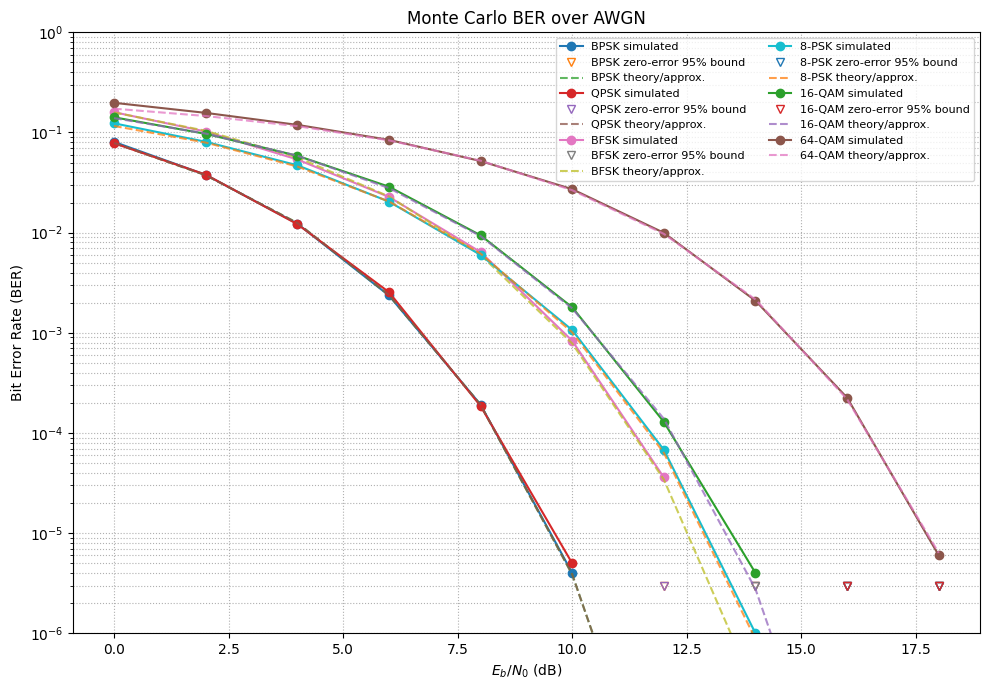

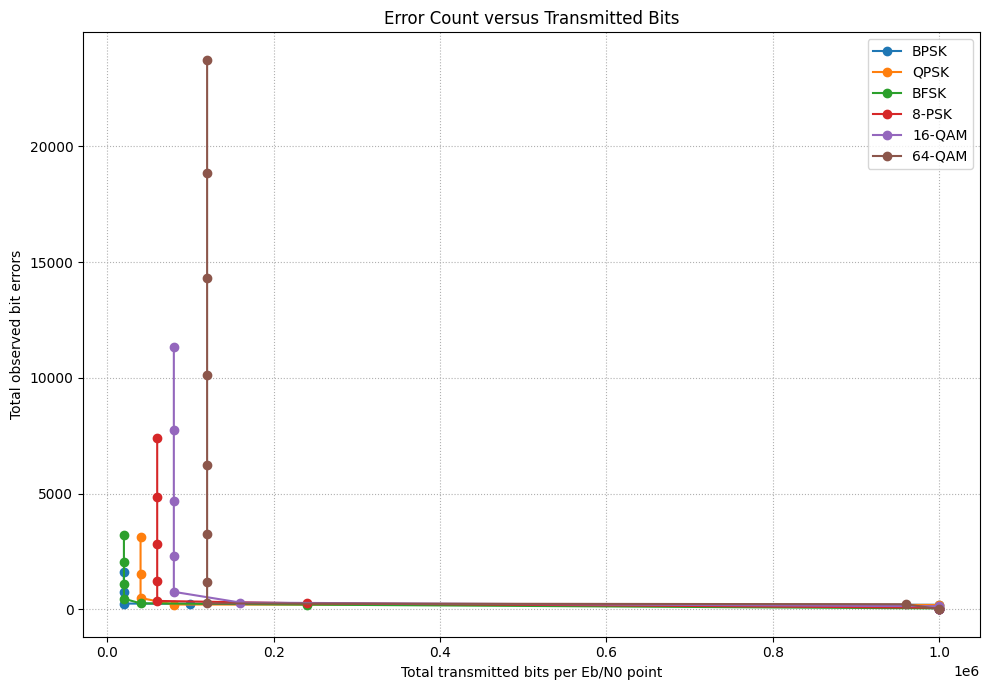


VALIDATION
BPSK   : Es=1.000, k=1, noiseless detection PASS
QPSK   : Es=1.000, k=2, noiseless detection PASS
BFSK   : Es=1.000, k=1, noiseless detection PASS
8-PSK  : Es=1.000, k=3, noiseless detection PASS
16-QAM : Es=1.000, k=4, noiseless detection PASS
64-QAM : Es=1.000, k=6, noiseless detection PASS
All normalization and noiseless detection checks passed.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

# ============================================================
# EXPERIMENT 12: MONTE CARLO BER OVER AWGN
# Modulations: BPSK, QPSK, coherent BFSK, 8-PSK, 16-QAM, 64-QAM
# ============================================================

# -------------------- Simulation parameters -----------------
EBN0_DB = np.arange(0, 19, 2)   # Eb/N0 in dB
MAX_BITS = 10**6               # Maximum transmitted bits per point
TARGET_ERRORS = 200             # Adaptive stopping threshold
BATCH_SYMBOLS = 20_000
RNG = np.random.default_rng(42)

MODULATIONS = ["BPSK", "QPSK", "BFSK", "8-PSK", "16-QAM", "64-QAM"]


# -------------------- Utility functions ---------------------
def gray_to_binary(g):
    """Convert a Gray-coded integer to its binary index."""
    b = g
    while g:
        g >>= 1
        b ^= g
    return b


def bits_to_integers(bits, k):
    """Group bits into k-bit integer labels."""
    return bits.reshape(-1, k).dot(
        1 << np.arange(k - 1, -1, -1)
    )


def integers_to_bits(labels, k):
    """Convert integer labels back to bit groups."""
    shifts = np.arange(k - 1, -1, -1)
    return ((labels[:, None] >> shifts) & 1).astype(np.uint8)


# -------------------- Constellation construction ------------
def make_constellation(name):
    """
    Return a normalized constellation indexed by binary labels.

    Average symbol energy Es = 1.
    Bits per symbol k = log2(M).
    The BFSK points are orthogonal complex baseband symbols.
    """
    if name == "BPSK":
        k = 1
        points = np.array([-1 + 0j, 1 + 0j])

    elif name == "BFSK":
        k = 1
        # Coherent orthogonal BFSK: inner product is zero.
        points = np.array([1 + 0j, 0 + 1j])

    elif name in ("QPSK", "8-PSK"):
        M = 4 if name == "QPSK" else 8
        k = int(np.log2(M))
        points = np.empty(M, dtype=complex)

        for label in range(M):
            phase_index = gray_to_binary(label)
            points[label] = np.exp(
                1j * 2 * np.pi * phase_index / M
            )

    elif name in ("16-QAM", "64-QAM"):
        M = 16 if name == "16-QAM" else 64
        k = int(np.log2(M))
        m_side = int(np.sqrt(M))
        k_axis = k // 2

        # Each axis uses Gray-coded PAM levels.
        levels = np.arange(-(m_side - 1), m_side, 2)
        points = np.empty(M, dtype=complex)

        for label in range(M):
            i_gray = label >> k_axis
            q_gray = label & (m_side - 1)

            i_index = gray_to_binary(i_gray)
            q_index = gray_to_binary(q_gray)

            points[label] = levels[i_index] + 1j * levels[q_index]

    else:
        raise ValueError("Unsupported modulation")

    # Explicit average constellation energy normalization.
    Es_before = np.mean(np.abs(points) ** 2)
    points = points / np.sqrt(Es_before)
    Es_after = np.mean(np.abs(points) ** 2)

    assert np.isclose(Es_after, 1.0)
    return points, k, Es_after


# -------------------- AWGN channel and receiver --------------
def transmit_receive(name, ebn0_db, n_symbols, rng):
    """
    Eb/N0 is defined per information bit.

    Es = 1 (normalized average symbol energy)
    Eb = Es/k
    N0 = Eb/(Eb/N0)
    Complex AWGN: E[|n|^2] = N0
    Each real component has variance N0/2.
    """
    constellation, k, Es = make_constellation(name)

    gamma_b = 10 ** (ebn0_db / 10.0)
    Eb = Es / k
    N0 = Eb / gamma_b
    complex_noise_variance = N0

    # Generate uniformly distributed information bits.
    tx_bits = rng.integers(
        0, 2, size=n_symbols * k, dtype=np.uint8
    )
    tx_labels = bits_to_integers(tx_bits, k)
    tx_symbols = constellation[tx_labels]

    # Complex AWGN: real and imaginary variances are N0/2.
    noise = np.sqrt(N0 / 2) * (
        rng.standard_normal(n_symbols)
        + 1j * rng.standard_normal(n_symbols)
    )
    rx_symbols = tx_symbols + noise

    # Minimum Euclidean-distance detector.
    # Process in chunks to limit memory use.
    detected_labels = np.empty(n_symbols, dtype=np.int64)
    detection_chunk = 5000

    for start in range(0, n_symbols, detection_chunk):
        stop = min(start + detection_chunk, n_symbols)
        distances = np.abs(
            rx_symbols[start:stop, None] - constellation[None, :]
        ) ** 2
        detected_labels[start:stop] = np.argmin(distances, axis=1)

    rx_bits = integers_to_bits(detected_labels, k).ravel()
    bit_errors = int(np.count_nonzero(tx_bits != rx_bits))

    return bit_errors, len(tx_bits), N0, k, Es


# -------------------- Theoretical BER ------------------------
def Q(x):
    return 0.5 * erfc(x / np.sqrt(2))


def theoretical_ber(name, ebn0_db):
    """Standard BER formulas; square QAM and PSK formulas are approximations."""
    gamma = 10 ** (np.asarray(ebn0_db) / 10.0)

    if name == "BPSK":
        return Q(np.sqrt(2 * gamma))

    if name == "QPSK":
        return Q(np.sqrt(2 * gamma))

    if name == "BFSK":
        # Coherent orthogonal binary FSK
        return Q(np.sqrt(gamma))

    if name == "8-PSK":
        k = 3
        # Gray-coded nearest-neighbour high-SNR approximation
        return (2 / k) * Q(
            np.sqrt(2 * k * gamma) * np.sin(np.pi / 8)
        )

    if name in ("16-QAM", "64-QAM"):
        M = 16 if name == "16-QAM" else 64
        k = int(np.log2(M))
        return (
            4 / k * (1 - 1 / np.sqrt(M))
            * Q(np.sqrt(3 * k * gamma / (M - 1)))
        )

    return None


# -------------------- Adaptive Monte Carlo driver ------------
results = {name: [] for name in MODULATIONS}

for name in MODULATIONS:
    print(f"\nSimulating {name}")

    constellation, k, Es = make_constellation(name)
    print(f"  Bits/symbol k = {k}")
    print(f"  Normalized average Es = {Es:.4f}")

    for ebn0_db in EBN0_DB:
        total_bits = 0
        total_errors = 0
        last_N0 = None

        while (
            total_errors < TARGET_ERRORS
            and total_bits < MAX_BITS
        ):
            # Do not exceed the maximum bit budget.
            remaining_bits = MAX_BITS - total_bits
            n_symbols = min(
                BATCH_SYMBOLS,
                remaining_bits // k
            )

            if n_symbols <= 0:
                break

            errors, bits_sent, N0, _, _ = transmit_receive(
                name, ebn0_db, n_symbols, RNG
            )

            total_errors += errors
            total_bits += bits_sent
            last_N0 = N0

        # Zero observed errors do NOT mean true BER is zero.
        if total_errors > 0:
            ber = total_errors / total_bits
        else:
            ber = np.nan

        # Approximate 95% upper confidence bound for zero errors.
        zero_error_upper = (
            1 - 0.05 ** (1 / total_bits)
            if total_errors == 0 else np.nan
        )

        results[name].append({
            "ebn0_db": ebn0_db,
            "errors": total_errors,
            "bits": total_bits,
            "ber": ber,
            "zero_error_upper": zero_error_upper,
            "N0": last_N0,
            "k": k,
            "Es": Es,
        })

        print(
            f"  Eb/N0={ebn0_db:2d} dB | "
            f"Errors={total_errors:4d} | "
            f"Bits={total_bits:7d} | "
            f"BER={ber:.3e}" if total_errors else
            f"  Eb/N0={ebn0_db:2d} dB | "
            f"Errors=0    | Bits={total_bits:7d} | "
            f"BER upper bound={zero_error_upper:.3e}"
        )

        print(f"    Complex noise variance N0 = {last_N0:.6g}")


# -------------------- Visualization 1: BER curves ------------
plt.figure(figsize=(10, 7))

for name in MODULATIONS:
    rows = results[name]
    x = np.array([r["ebn0_db"] for r in rows])
    errors = np.array([r["errors"] for r in rows])
    bits = np.array([r["bits"] for r in rows])
    ber = np.array([r["ber"] for r in rows])
    upper = np.array([r["zero_error_upper"] for r in rows])

    # Plot nonzero measured BER values.
    valid = errors > 0
    plt.semilogy(
        x[valid], ber[valid], "o-", label=f"{name} simulated"
    )

    # Zero-error points are shown as upper bounds, not zero BER.
    zero = errors == 0
    if np.any(zero):
        plt.semilogy(
            x[zero], upper[zero], "v",
            markerfacecolor="none",
            linestyle="none",
            label=f"{name} zero-error 95% bound"
        )

    # Overlay theoretical BER where a standard expression is valid.
    theory = theoretical_ber(name, x)
    if theory is not None:
        plt.semilogy(
            x, theory, "--", alpha=0.75,
            label=f"{name} theory/approx."
        )

plt.xlabel(r"$E_b/N_0$ (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("Monte Carlo BER over AWGN")
plt.grid(True, which="both", linestyle=":")
plt.ylim(1e-6, 1)
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


# -------------------- Visualization 2: errors vs bits --------
plt.figure(figsize=(10, 7))

for name in MODULATIONS:
    rows = results[name]
    x = np.array([r["bits"] for r in rows])
    y = np.array([r["errors"] for r in rows])

    plt.plot(x, y, "o-", label=name)

plt.xlabel("Total transmitted bits per Eb/N0 point")
plt.ylabel("Total observed bit errors")
plt.title("Error Count versus Transmitted Bits")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()


# -------------------- Normalization/noiseless validation -----
print("\nVALIDATION")
for name in MODULATIONS:
    points, k, Es = make_constellation(name)
    assert np.isclose(np.mean(np.abs(points)**2), 1.0)

    # Test that the minimum-distance detector recovers every
    # constellation point exactly when there is no noise.
    d = np.abs(points[:, None] - points[None, :]) ** 2
    detected = np.argmin(d, axis=1)
    assert np.array_equal(detected, np.arange(len(points)))

    print(
        f"{name:7s}: Es={Es:.3f}, k={k}, "
        "noiseless detection PASS"
    )

print("All normalization and noiseless detection checks passed.")